# Kinematic slip on a triangular mesh, step 2: the Bayesian inversion with AlTar

[Step 1](step1_csi.ipynb) made a synthetic kinematic data set on a curved, slab-like fault with CSI, and inverted it with a linear least squares solution: the slip of each patch in each time step it may slip in, smoothed in space and time, with the hypocenter fixed at the true one. This step inverts the same data with AlTar 2, for the posterior of the parameters of the rupture itself:

- the final slip of each patch, along and across the plate convergence;
- the rise time of each patch;
- the rupture velocity, one for each of 16 groups of patches;
- the hypocenter, in the surface coordinates of the fault.

That is 128 × 3 + 16 + 2 = 402 parameters, against the 11470 slip windows of the least squares solution. AlTar's kinematic model on triangular meshes, `altar.models.seismic.kinematicmesh`, turns them into the slip history, the model step 1 made the data with: the rupture front spreads from the hypocenter by the fast iterative method, on a mesh refined from the patches, and each source point of a patch slips with a triangular source time function, starting when the front reaches it.

The data are linear in the slip history, but the slip history isn't linear in these parameters. AlTar samples their posterior with CATMIP, annealed from the prior, and Hamiltonian Monte Carlo, with the exact gradient of the kinematic model (the adjoint of the eikonal solver and of the source time functions). The result has no time windows, no smoothing weight and no fixed hypocenter to choose, and comes with uncertainties.

This notebook needs AlTar 2 with a GPU (see its [Installation Guide](https://altar2.readthedocs.io/en/latest/guide/Installation.html)), and the files step 1 wrote to `input/`.

> **Note:** the results shown here come from runs made beforehand, with these configuration files, on the same data; the cascaded inversion took 5.8 hours on one GPU (an NVIDIA RTX PRO 6000). A cell that runs an inversion skips it if its results are in `results/` already; remove them to run it again.

In [1]:
import os
import h5py
import numpy as np
import matplotlib.pyplot as plt

# the mesh, and what step 1 saved for the comparison
with h5py.File('input/mesh.h5') as h5:
    V, F, uv = (np.asarray(h5[k]) for k in ['vertices', 'faces', 'uv'])
    groups = np.asarray(h5['groups/velocity'])
with h5py.File('input/synthetic.h5') as h5:
    true = {k: np.asarray(v) for k, v in h5['true'].items()}
    Mb_ls = np.asarray(h5['leastsquares/Mb'])
    mu, area, dt = np.asarray(h5['mu']), np.asarray(h5['area']), float(h5['dt'][()])
    stations = [s.decode() for s in h5['stations']]
Np, Nt = F.shape[0], true['Mb'].shape[0]
print(f"{Np} patches, {groups.max() + 1} velocity groups, {Nt} time steps of {dt:g} s")

def summary(run):
    # the beta steps of a run, and its acceptance rates, from its BetaStatistics.txt
    stats = np.loadtxt(f'{run}/BetaStatistics.txt', delimiter=',', skiprows=1)[1:]
    acceptance = stats[:, 3] / stats[:, 3:].sum(1)
    print(f"{run}: {int(stats[-1, 0])} beta steps to beta = {stats[-1, 1]:g}; "
          f"acceptance rate {acceptance.min():.2f} to {acceptance.max():.2f}")

128 patches, 16 velocity groups, 85 time steps of 1 s


## The static inversion

The inversion is cascaded: the slips first get the posterior of the static data alone, which the kinematic inversion then starts from. The static model, `altar.models.seismic.static`, is linear in the slips; its Green's functions have a column per patch for slip across the convergence, then a column per patch along it, as the rakes of step 1. The priors are those of Gombert et al. (2018) for the Pedernales earthquake: slip along the convergence uniform between -1 and 15 m, across it gaussian with a standard deviation of 0.5 m. This run takes about a minute.

In [2]:
print(open('static.pfg').read())

; step 2, the static inversion: the slips from the static data alone, gps and line of sight; the
; priors of Gombert et al. (2018), slip along the convergence U(-1, 15) m, across it N(0, 0.5) m
slipmodel:
    model = altar.models.seismic.static
    model:
        case = input
        patches = 128
        parameters = 2*{slipmodel.model.patches}
        green = static.gf.h5
        dataobs:
            observations = 188
            data_file = static.data.h5
            cd_file = static.Cd.h5
        ; the columns of the green's functions: across, then along the convergence
        psets_list = [across, parallel]
        psets:
            across = contiguous
            parallel = contiguous
            across:
                count = {slipmodel.model.patches}
                prior = gaussian
                prior.mean = 0
                prior.sigma = 0.5
            parallel:
                count = {slipmodel.model.patches}
                prior = uniform
                prior.sup

In [3]:
if not os.path.exists('results/static/step_final.h5'):
    !slipmodel.plexus sample --config=static.pfg > static.log 2>&1
summary('results/static')

results/static: 75 beta steps to beta = 1; acceptance rate 0.69 to 0.89


## The cascaded inversion

The model is an ensemble, `altar.models.ensemble`, of the static model and the kinematic one, sharing the slips. With `cascaded = True`, the static model contributes its full likelihood at every β step, while the kinematic one is annealed. The slips start from the static posterior (`prep = preset`); the rise times, the rupture velocities and the hypocenter from their priors. The prior of the hypocenter is centered 5 km away from the true one, as a catalog's location might be.

The sampler: 4096 chains, and at each β step 40 HMC trajectories of 25 leapfrog steps, about a thousand, long enough for the chains to forget where they started; a second run with another seed gave the same posterior, its means within a median 0.04 to 0.10 posterior standard deviations of these, parameter set by parameter set. The [AlTar guide](https://altar2.readthedocs.io/en/latest/guide/Convergence.html) recommends cheaper settings for kinematic inversions now: fewer chains, with walks that go on until the samples decorrelate. In single precision (`job.gpuprecision = float32`) the run is several times faster than in double, and its acceptance rate stays at its target throughout.

In [4]:
print(open('cascaded.pfg').read())

; step 2, the cascaded inversion: the static data at beta = 1 throughout, the waveforms annealed; the
; slips start from the static posterior; a rise time per patch, a rupture velocity per group of
; patches, and the hypocenter, with a prior 5 km off the true one, as a catalog's might be
slipmodel:
    model = altar.models.ensemble
    model:
        case = input
        patches = 128
        psets_list = [across, parallel, risetime, rupturevelocity, hypo_strike, hypo_dip]
        psets:
            across = contiguous
            parallel = contiguous
            risetime = contiguous
            rupturevelocity = contiguous
            hypo_strike = contiguous
            hypo_dip = contiguous
            across:
                count = {slipmodel.model.patches}
                prep = preset
                prep.input_file = results/static/step_final.h5
                prep.dataset = ParameterSets/across
                prior = gaussian
                prior.mean = 0
                

In [5]:
if not os.path.exists('results/cascaded/step_final.h5'):
    !slipmodel.plexus sample --config=cascaded.pfg > cascaded.log 2>&1
summary('results/cascaded')

results/cascaded: 72 beta steps to beta = 1; acceptance rate 0.70 to 0.71


## The model at the true parameters

For reference, the fit of the true parameters, in the order of the parameter sets of the cascaded inversion: a chi-square per datum close to 1, the noise, for the waveforms and the static data.

In [6]:
np.savetxt('results/truth.txt', np.concatenate([true[k] for k in ['across', 'parallel', 'risetime', 'rupturevelocity', 'hypocenter']])[None, :])
!slipmodel.plexus forward --config=cascaded.pfg --slipmodel.forward.theta=results/truth.txt \
    --slipmodel.forward.output=results/truth.h5 > truth.log 2>&1
with h5py.File('results/truth.h5') as h5:
    for model in ['kinematic', 'static']:
        print(f"{model}: chi-square per datum {float(h5[f'{model}/fit/mean_model/chi2'][()]) / float(h5[f'{model}/fit/observations'][()]):.3f}")

kinematic: chi-square per datum 1.007
static: chi-square per datum 1.113


## The fit to the data

The `forward` action runs the models of the ensemble on the posterior mean and on the posterior samples, each on its own data, and reports the fit: the chi-square per datum, the variance reduction, and how many observations fall in the predictive band. It also saves the predictions, and the slip history of the kinematic model.

In [7]:
!slipmodel.plexus forward --config=cascaded.pfg --slipmodel.forward.theta=results/cascaded/step_final.h5 \
    --slipmodel.forward.output=results/cascaded/forward.h5 --slipmodel.forward.samples=2000 > forward.log 2>&1
!grep -v -E "^journal|^ -- forward:|^\s*$" forward.log | sed -e 's/^ -- //'

current worker 0 with device NVIDIA RTX PRO 6000 Blackwell Server Edition id 0
kinematic mesh: 128 patches, 6561 vertices, spacing 2.28 km, 9 source points per patch
static:
  188 observations, full covariance
  data sigma rms 0.00800598, with C_p 0.00800598
  results/cascaded/step_final.h5:
                             chi^2/N        VR         rms         log L
    mean model                0.6387    0.9996    0.006606       695.355
    predictive mean           0.6387    0.9996    0.006606       695.355
    best-fitting sample       0.7535    0.9995    0.007068       684.568
    samples: log L 664.667 +- 5.86, chi^2/N median 0.9614; 2 var(log L) = 68.8 (the effective number of parameters, for a gaussian posterior)
  observations within the predictive band: 83.0% at 1 sigma, 98.4% at 2 sigma
kinematic:
  8640 observations, C = 0.005^2 I
  data sigma rms 0.005, with C_p 0.005
  results/cascaded/step_final.h5:
                             chi^2/N        VR         rms         log L
   

## The posterior against the truth and the least squares solution

The posterior samples are in `results/cascaded/step_final.h5`, two datasets per parameter set: `<name>_physical`, the values of the parameters, and `<name>_sampling`, those AlTar samples, the logits of the ones with uniform priors.

In [8]:
names = ['across', 'parallel', 'risetime', 'rupturevelocity', 'hypo_strike', 'hypo_dip']
with h5py.File('results/cascaded/step_final.h5') as h5:
    P = h5['ParameterSets']
    post = {s: np.asarray(P[f'{s}_physical'] if f'{s}_physical' in P else P[s], dtype=float) for s in names}
post['hypocenter'] = np.column_stack([post.pop('hypo_strike')[:, 0], post.pop('hypo_dip')[:, 0]])
samples = post['parallel'].shape[0]
with h5py.File('results/cascaded/forward.h5') as h5:
    Mb_post = np.asarray(h5['kinematic/Mb/mean']).reshape(Nt, 2, Np)
    predicted = {model: np.asarray(h5[f'{model}/data/mean_model']) for model in ['kinematic', 'static']}
    band = np.asarray(h5['kinematic/data/std'])
    observed = {model: np.asarray(h5[f'{model}/data/observed']) for model in ['kinematic', 'static']}
    chi2 = {model: float(h5[f'{model}/fit/mean_model/chi2'][()]) / float(h5[f'{model}/fit/observations'][()])
            for model in ['kinematic', 'static']}

# the final slips and the moment magnitudes: the truth, the least squares solution, and each posterior sample
magnitude = lambda slip: 2 / 3 * (np.log10((mu * area * 1e6 * slip).sum(-1)) - 9.1)
slip_ls = Mb_ls.sum(0) * dt
Mw = magnitude(np.hypot(post['across'], post['parallel']))
Mw_along = magnitude(post['parallel'])
mean, sd = {s: v.mean(0) for s, v in post.items()}, {s: v.std(0) for s, v in post.items()}
print(f"{samples} posterior samples")
print(f"{'':36s}{'truth':>10s}{'least squares':>16s}{'AlTar':>18s}")
corr = lambda a, b: np.corrcoef(a, b)[0, 1]
print(f"{'slip along, correlation with truth':36s}{'':10s}{corr(slip_ls[1], true['parallel']):16.3f}{corr(mean['parallel'], true['parallel']):18.3f}")
print(f"{'slip along, rms error (m)':36s}{'':10s}{np.sqrt(((slip_ls[1] - true['parallel']) ** 2).mean()):16.2f}"
      f"{np.sqrt(((mean['parallel'] - true['parallel']) ** 2).mean()):18.2f}")
print(f"{'largest slip along (m)':36s}{true['parallel'].max():10.2f}{slip_ls[1].max():16.2f}{mean['parallel'].max():18.2f}")
print(f"{'slip across, correlation with truth':36s}{'':10s}{corr(slip_ls[0], true['across']):16.3f}{corr(mean['across'], true['across']):18.3f}")
print(f"{'Mw, from the slip along':36s}{magnitude(true['parallel']):10.3f}"
      f"{magnitude(slip_ls[1]):16.3f}{Mw_along.mean():12.3f} ± {Mw_along.std():.3f}")
print(f"{'Mw, from the magnitude of the slip':36s}{magnitude(np.hypot(true['across'], true['parallel'])):10.3f}"
      f"{magnitude(np.hypot(*slip_ls)):16.3f}{Mw.mean():12.3f} ± {Mw.std():.3f}")
print(f"{'hypocenter along strike (km)':36s}{true['hypocenter'][0]:10.1f}{'(fixed)':>16s}{mean['hypocenter'][0]:12.1f} ± {sd['hypocenter'][0]:.1f}")
print(f"{'hypocenter down dip (km)':36s}{true['hypocenter'][1]:10.1f}{'(fixed)':>16s}{mean['hypocenter'][1]:12.1f} ± {sd['hypocenter'][1]:.1f}")
vr = lambda d, p: 1 - ((d - p) ** 2).sum() / (d ** 2).sum()
with h5py.File('input/static.gf.h5') as h5:
    G_static = np.asarray(h5['static.gf'])
with h5py.File('input/kinematicG.gf.h5') as h5:
    waveforms_ls = Mb_ls.ravel() @ np.asarray(h5['kinematicG.gf'])
print(f"{'waveforms, variance reduction':36s}{'':10s}{vr(observed['kinematic'], waveforms_ls):16.3f}{vr(observed['kinematic'], predicted['kinematic']):18.3f}")
print(f"{'static, variance reduction':36s}{'':10s}{vr(observed['static'], G_static @ slip_ls.ravel()):16.4f}{vr(observed['static'], predicted['static']):18.4f}")
print(f"chi-square per datum of AlTar's mean model: waveforms {chi2['kinematic']:.2f}, static {chi2['static']:.2f}")

4096 posterior samples
                                         truth   least squares             AlTar
slip along, correlation with truth                       0.990             0.979
slip along, rms error (m)                                 0.16              0.23
largest slip along (m)                    5.57            5.33              5.93
slip across, correlation with truth                      0.506             0.538
Mw, from the slip along                  7.900           7.900       7.899 ± 0.003
Mw, from the magnitude of the slip       7.901           7.914       7.964 ± 0.007
hypocenter along strike (km)             125.0         (fixed)       124.8 ± 1.4
hypocenter down dip (km)                  55.0         (fixed)        52.4 ± 1.1


waveforms, variance reduction                            0.991             0.990
static, variance reduction                              0.9996            0.9996
chi-square per datum of AlTar's mean model: waveforms 1.02, static 0.64


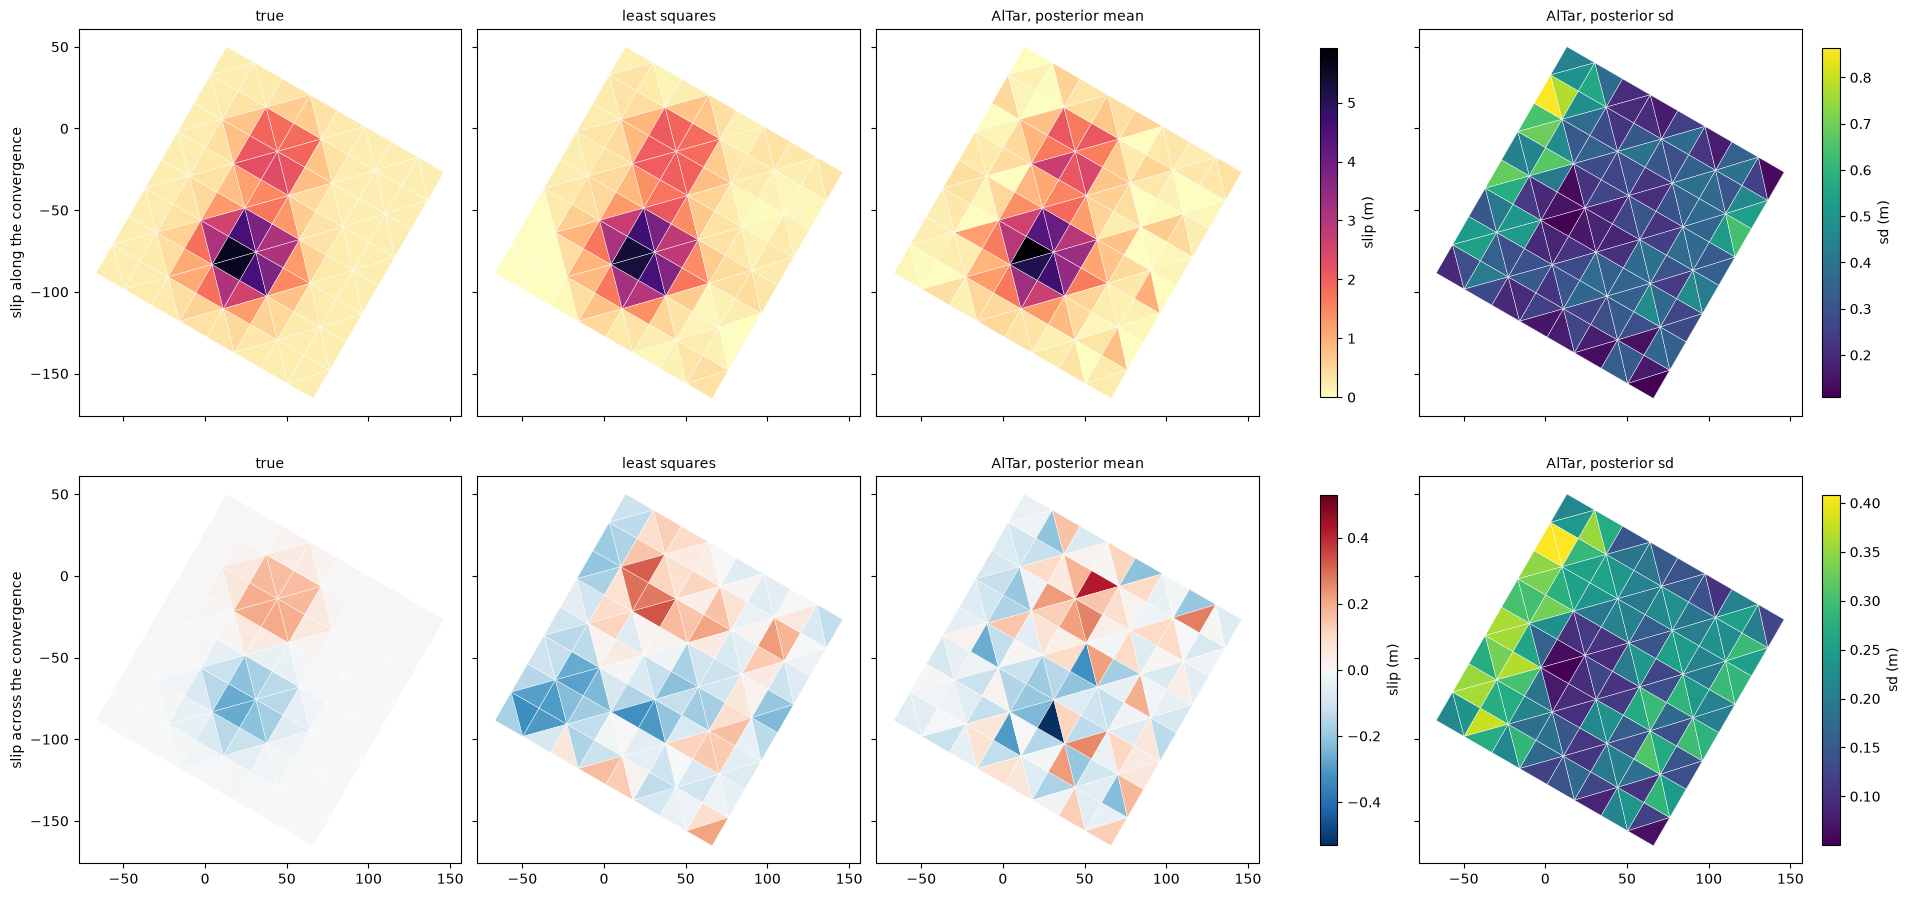

In [9]:
# the final slip: the truth, the least squares solution, the posterior mean and its standard deviation
fig, axes = plt.subplots(2, 4, figsize=(19, 9), sharex=True, sharey=True, layout='constrained')
for row, (k, name, label, cmap) in enumerate([(1, 'parallel', 'along the convergence', 'magma_r'),
                                              (0, 'across', 'across the convergence', 'RdBu_r')]):
    maps = [true[name], slip_ls[k], mean[name]]
    hi = max(np.abs(m).max() for m in maps)
    lo = 0 if k == 1 else -hi
    for col, (values, title) in enumerate(zip(maps, ['true', 'least squares', 'AlTar, posterior mean'])):
        pc = axes[row, col].tripcolor(V[:, 0], V[:, 1], F, facecolors=values, cmap=cmap, vmin=lo, vmax=hi, edgecolors='w', lw=0.3)
        axes[row, col].set_title(title, fontsize=10)
    axes[row, 0].set_ylabel(f'slip {label}')
    fig.colorbar(pc, ax=axes[row, :3], label='slip (m)', shrink=0.8)
    pc = axes[row, 3].tripcolor(V[:, 0], V[:, 1], F, facecolors=sd[name], cmap='viridis', edgecolors='w', lw=0.3)
    axes[row, 3].set_title('AlTar, posterior sd', fontsize=10)
    fig.colorbar(pc, ax=axes[row, 3], label='sd (m)', shrink=0.8)
for ax in axes.ravel():
    ax.set_aspect('equal')
plt.show()

The least squares solution needs the hypocenter and gets the timing of the rupture only through the slip of each time window; AlTar samples the timing parameters themselves. Their posterior, against the truth:

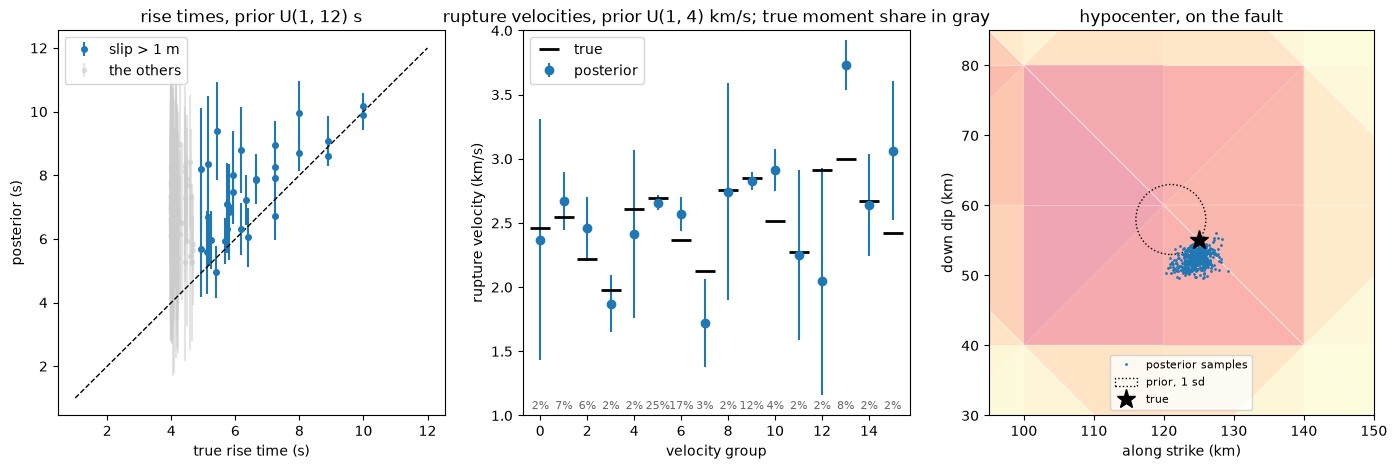

In [10]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(17, 5))
# the rise times, where the fault slips
slipping = true['parallel'] > 1.0
ax1.errorbar(true['risetime'][slipping], mean['risetime'][slipping], yerr=sd['risetime'][slipping], fmt='o', ms=4, label='slip > 1 m')
ax1.errorbar(true['risetime'][~slipping], mean['risetime'][~slipping], yerr=sd['risetime'][~slipping], fmt='.', color='0.8', alpha=0.5, label='the others')
ax1.plot([1, 12], [1, 12], 'k--', lw=1)
ax1.set_xlabel('true rise time (s)'); ax1.set_ylabel('posterior (s)'); ax1.set_title('rise times, prior U(1, 12) s'); ax1.legend()
# the rupture velocities of the groups, with the share of the moment each group releases
share = np.bincount(groups, weights=mu * area * true['parallel']) / (mu * area * true['parallel']).sum()
order = np.arange(groups.max() + 1)
ax2.errorbar(order, mean['rupturevelocity'], yerr=sd['rupturevelocity'], fmt='o', label='posterior')
ax2.plot(order, true['rupturevelocity'], 'k_', ms=14, mew=2, label='true')
for g in order:
    ax2.annotate(f'{100 * share[g]:.0f}%', (g, 1.05), ha='center', fontsize=8, color='0.4')
ax2.set_ylim(1, 4); ax2.set_xlabel('velocity group'); ax2.set_ylabel('rupture velocity (km/s)')
ax2.set_title('rupture velocities, prior U(1, 4) km/s; true moment share in gray'); ax2.legend(loc='upper left')
# the hypocenter, on the fault
ax3.tripcolor(uv[:, 0], uv[:, 1], F, facecolors=true['parallel'], cmap='magma_r', edgecolors='w', lw=0.3, alpha=0.5)
ax3.plot(*post['hypocenter'][::8].T, '.', ms=2, color='C0', label='posterior samples')
ax3.add_patch(plt.Circle((121.0, 58.0), 5.0, fill=False, ls=':', color='k', label='prior, 1 sd'))
ax3.plot(*true['hypocenter'], 'k*', ms=14, label='true')
ax3.set_aspect('equal'); ax3.set_xlabel('along strike (km)'); ax3.set_ylabel('down dip (km)')
ax3.set_xlim(95, 150); ax3.set_ylim(30, 85); ax3.set_title('hypocenter, on the fault'); ax3.legend(fontsize=8)
plt.show()

The rupture velocities are resolved where the fault slips, and stay near their prior where it doesn't: a group that releases little moment leaves little trace in the data. The rise times are less resolved than the velocities: the waveforms are bandpassed at periods of 12 to 67 s, longer than the 4 to 10 s rise times, so they see the centroid time of a patch better than how long it slips.

Some errors are larger than their standard deviations: the hypocenter is 2.6 km up dip of the true one, 2.4 standard deviations, and the rupture velocity of group 13, just north of it, is 3.7 ± 0.2 km/s against a true 3.0. They are one trade-off rather than two misses: from a hypocenter up dip, a faster rupture reaches the northern asperity on time. The posterior is tighter than its errors here because the data constrain the timing of the rupture, the onsets of the patches, better than how it splits between the hypocenter and the velocities.

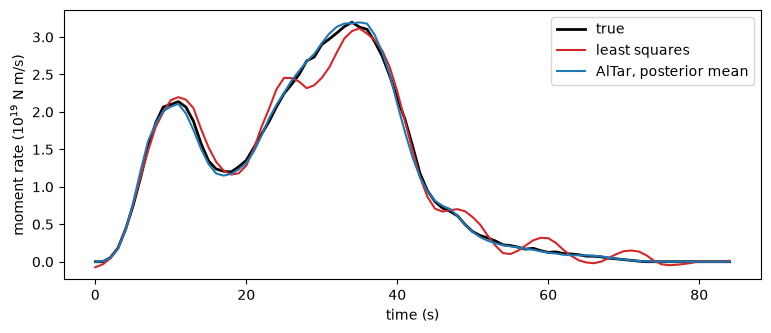

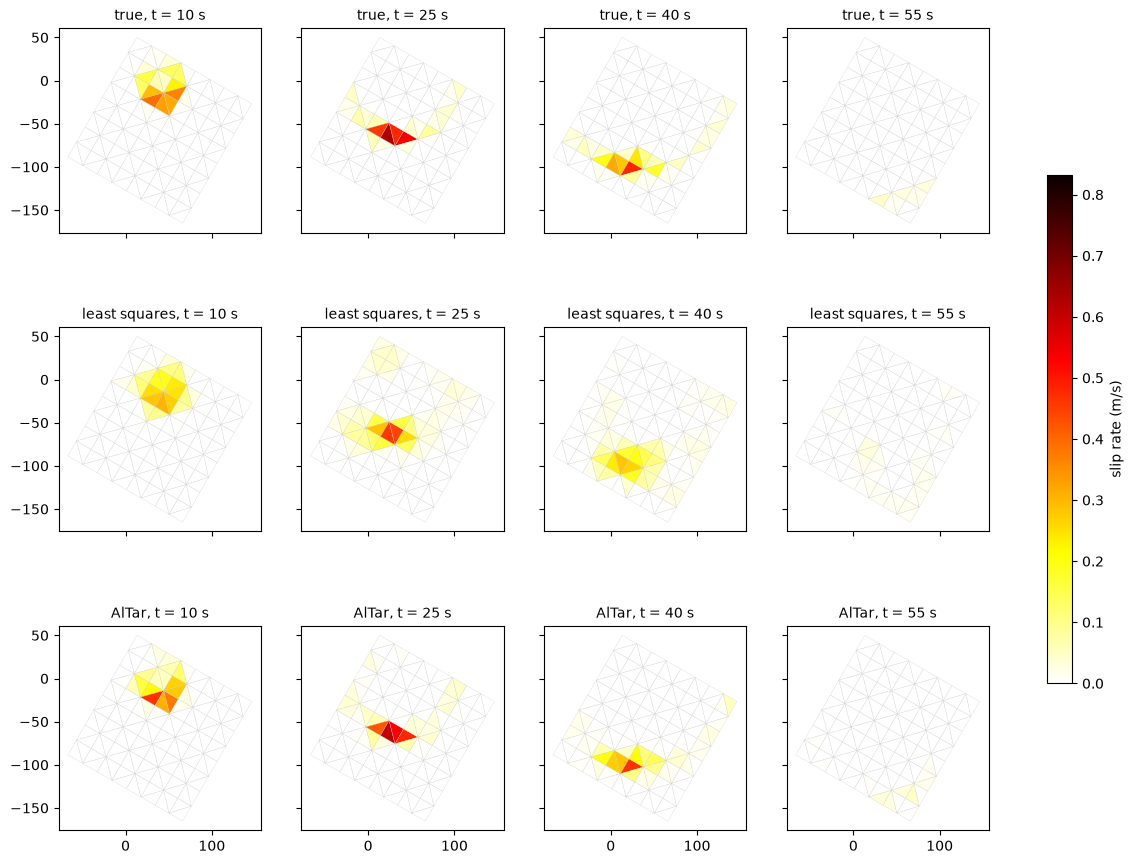

In [11]:
# the moment rate and the slip rates, of the slip along the convergence: across it, the slip is mostly unresolved, and its
# spread, or the noise the least squares solution fits, would add to the moment of the magnitude of the slip
rate_moment = lambda history: (mu * area * 1e6 * history[:, 1]).sum(1) / dt
tk = np.arange(Nt) * dt
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(tk, rate_moment(true['Mb']) / 1e19, 'k', lw=2, label='true')
ax.plot(tk, rate_moment(Mb_ls) / 1e19, 'C3', label='least squares')
ax.plot(tk, rate_moment(Mb_post) / 1e19, 'C0', label='AlTar, posterior mean')
ax.set_xlabel('time (s)'); ax.set_ylabel('moment rate (10$^{19}$ N m/s)'); ax.legend()
plt.show()

times = [10, 25, 40, 55]
histories = {'true': true['Mb'], 'least squares': Mb_ls, 'AlTar': Mb_post}
rates = {k: h[:, 1] / dt for k, h in histories.items()}
peak = rates['true'].max()
fig, axes = plt.subplots(3, len(times), figsize=(15, 11), sharex=True, sharey=True)
for col, tt in enumerate(times):
    for row, title in enumerate(histories):
        ax = axes[row, col]
        pc = ax.tripcolor(V[:, 0], V[:, 1], F, facecolors=np.clip(rates[title][tt], 0, None), cmap='hot_r', vmin=0, vmax=peak,
                          edgecolors='0.8', lw=0.2)
        ax.set_aspect('equal'); ax.set_title(f'{title}, t = {tt} s', fontsize=10)
fig.colorbar(pc, ax=axes, label='slip rate (m/s)', shrink=0.6)
plt.show()

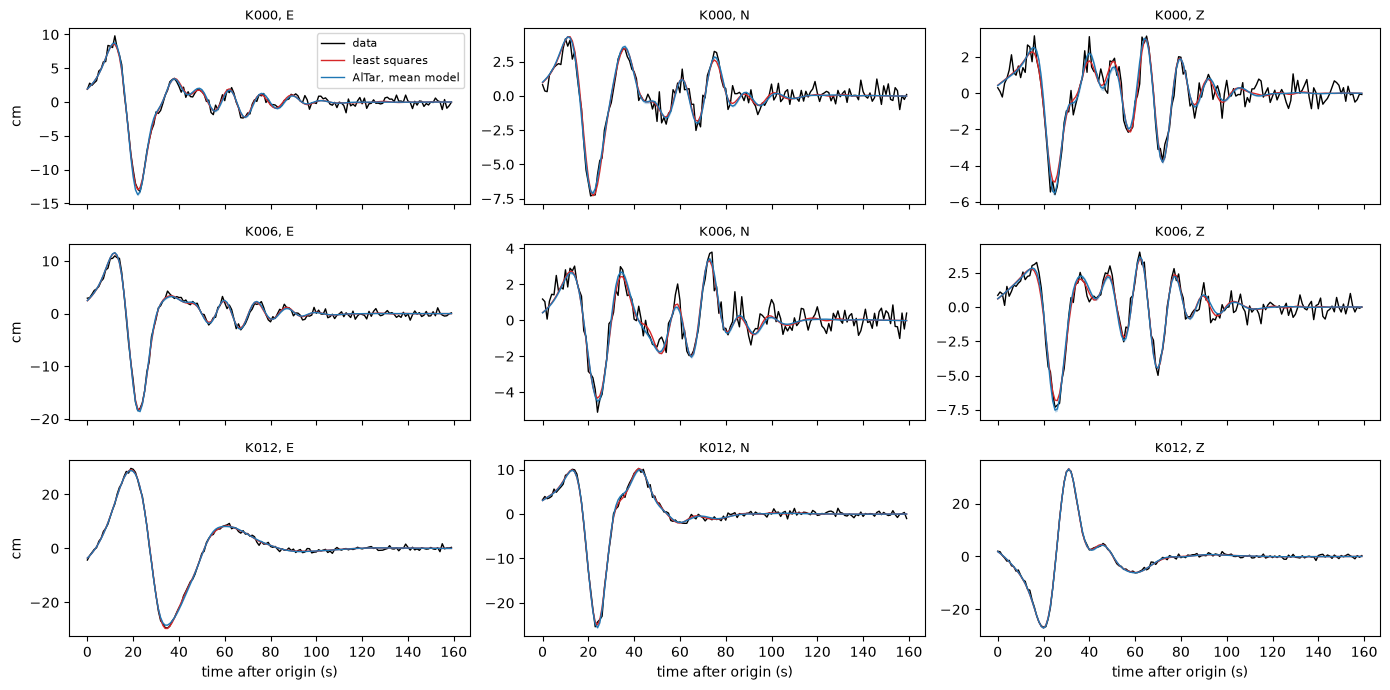

In [12]:
# the waveforms at three stations: the data, the least squares fit, and AlTar's mean model with the spread of the samples
shape = (len(stations), 3, -1)
data, ls, alt, spread = (x.reshape(shape) for x in [observed['kinematic'], waveforms_ls, predicted['kinematic'], band])
t = np.arange(data.shape[-1]) * dt
fig, axes = plt.subplots(3, 3, figsize=(14, 7), sharex=True)
for row, s in enumerate([0, 6, 12]):
    for c in range(3):
        ax = axes[row, c]
        ax.plot(t, 100 * data[s, c], 'k', lw=1, label='data')
        ax.plot(t, 100 * ls[s, c], 'C3', lw=1, label='least squares')
        ax.fill_between(t, 100 * (alt[s, c] - spread[s, c]), 100 * (alt[s, c] + spread[s, c]), color='C0', alpha=0.3, lw=0)
        ax.plot(t, 100 * alt[s, c], 'C0', lw=1, label='AlTar, mean model')
        ax.set_title(f"{stations[s]}, {'ENZ'[c]}", fontsize=9)
    axes[row, 0].set_ylabel('cm')
axes[0, 0].legend(fontsize=8)
for ax in axes[-1]:
    ax.set_xlabel('time after origin (s)')
fig.tight_layout()
plt.show()

## Summary

Both inversions fit the waveforms and the static data to the noise, and recover the two asperities, the moment along the convergence and the moment rate. They differ in what they assume and what they give:

- The least squares solution is linear: a dense solve for each smoothing weight. Given the true hypocenter, a window of rupture velocities for its time windows and the weight that fits the noise, it is the closer of the two to the true slip here, its correlation 0.990 against 0.979; but it has no uncertainties, its slip along the convergence may be negative, and the timing of the rupture is only implicit in its 11470 slip windows.
- AlTar samples the parameters of the rupture itself, 402 of them, from the same slip history model the data were made with: it locates the hypocenter, from a prior 5 km off, to within 2.6 km of the true one, recovers the rupture velocities where the fault slips, follows the true moment rate closely, where the least squares one oscillates around it, and gives the uncertainty of every parameter, with the bounds of the priors keeping the slip along the convergence positive. It took 5.8 hours on a GPU.

The posterior also shows what the data can't tell: the slip across the convergence over much of the fault, the slip near the trench, far from the stations on land, the rise times, and the rupture velocities of the groups that don't slip, which stay near their priors.